# A4 — Multinomial Naive Bayes

**Project:** TruthLens AI — Fake News Detection System Using Machine Learning
**Dataset:** `data/cleaned_dataset.csv` (LIAR benchmark, 12,836 short political statements)
**Task:** four-class classification — Real, Misleading, Partially False, Fake

## Objective

Implement and evaluate Multinomial Naive Bayes on the four-class task, including the effect of the Laplace smoothing parameter alpha.

## Method summary

1. Load and audit the supplied dataset (label mapping, missing text, duplicates, splits).
2. Apply the shared deterministic text cleaning used by the web application.
3. Extract word (1–2 gram) and character (3–5 gram) TF-IDF features **inside** a scikit-learn Pipeline.
4. Train on the predefined training split only; tune on the validation split.
5. Evaluate once on the untouched test split and report accuracy, precision, recall, F1 (weighted and macro) and a confusion matrix.
6. Save the fitted pipeline so the FastAPI backend can reuse exactly the same preprocessing.

This notebook is self-contained and runs top to bottom from the `notebooks/` folder.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import sys, json

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.truthlens.config import CLASS_NAMES, LABEL_MAPPING, TEST_SIZE, RANDOM_STATE
from src.truthlens.data import load_dataset
from src.truthlens.preprocessing import preprocess_text
from src.truthlens.pipeline import default_candidates, evaluate_predictions
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

plt.style.use("dark_background")
pd.set_option("display.max_colwidth", 90)
print("Project root:", PROJECT_ROOT)

Project root: /home/user/work/TruthLens-AI


## 2. Load the dataset and inspect it

In [2]:
bundle = load_dataset()
train_df, valid_df, test_df = bundle.train, bundle.valid, bundle.test

print(f"Train      : {len(train_df):,} rows")
print(f"Validation : {len(valid_df):,} rows")
print(f"Test       : {len(test_df):,} rows")
print(f"Total used : {bundle.all_rows:,} rows")
print("\nAudit:", json.dumps({k: v for k, v in bundle.report.items() if k != "class_distribution_by_split"}, indent=2)[:900])

Train      : 10,252 rows
Validation : 1,279 rows
Test       : 1,279 rows
Total used : 12,810 rows

Audit: {
  "source_file": "/home/user/work/TruthLens-AI/data/cleaned_dataset.csv",
  "initial_rows": 12836,
  "rows_after_basic_cleaning": 12836,
  "duplicate_rows_removed": 26,
  "duplicates_inside_train": 0,
  "split_fallback_used": false,
  "split_counts": {
    "train": 10252,
    "valid": 1279,
    "test": 1279
  },
  "class_distribution": {
    "Real": 2063,
    "Misleading": 2466,
    "Partially False": 4746,
    "Fake": 3561
  }
}


In [3]:
train_df[["text", "raw_label", "label", "split"]].head(8)

,text,raw_label,label,split
0,Says the Annies List political group supports third-trimester abortions on demand.,false,Fake,train
1,When did the decline of coal start? It started when natural gas took off that started ...,half-true,Partially False,train
2,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of ...",mostly-true,Misleading,train
3,Health care reform legislation is likely to mandate free sex change surgeries.,false,Fake,train
4,The economic turnaround started at the end of my term.,half-true,Partially False,train
5,The Chicago Bears have had more starting quarterbacks in the last 10 years than the to...,true,Real,train
6,Jim Dunnam has not lived in the district he represents for years now.,barely-true,Partially False,train
7,"""I'm the only person on this stage who has worked actively just last year passing, alo...",half-true,Partially False,train


## 3. Label mapping and class distribution

The original PolitiFact six-point scale is mapped onto four project categories. The mapping is
validated row-by-row by `load_dataset()` (it raises an error if `label` disagrees with the
documented mapping), so no label can be silently mis-assigned.

In [4]:
mapping_table = pd.DataFrame(
    [{"raw_label": raw, "mapped_label": mapped} for raw, mapped in LABEL_MAPPING.items()]
)
display(mapping_table)

dist = train_df["label"].value_counts().reindex(CLASS_NAMES)
display(pd.DataFrame({"train_count": dist, "share": (dist / dist.sum()).round(4)}))

valid_counts = valid_df["label"].value_counts().reindex(CLASS_NAMES)
test_counts = test_df["label"].value_counts().reindex(CLASS_NAMES)
display(pd.DataFrame({"valid_count": valid_counts, "test_count": test_counts}))

,raw_label,mapped_label
0,true,Real
1,mostly-true,Misleading
2,half-true,Partially False
3,barely-true,Partially False
4,false,Fake
5,pants-fire,Fake


,train_count,share
label,,
Real,1681,0.1640
Misleading,1965,0.1917
Partially False,3774,0.3681
Fake,2832,0.2762


,valid_count,test_count
label,,
Real,169,210
Misleading,250,249
Partially False,485,480
Fake,375,340


## 4. Text preprocessing

The same function (`src/truthlens/preprocessing.py`) is used by training, notebooks and the
production API. Stop-word removal is handled by the TF-IDF vectorizer, which is stored inside the
saved pipeline, so inference and training can never drift apart.

In [5]:
example = train_df.iloc[0]["text"]
print("RAW      :", example)
print("CLEANED  :", preprocess_text(example))

# Apply to every split (the dataset ships a clean_text column, but we recompute it so the
# exact code path used in production is exercised during training too).
for part in (train_df, valid_df, test_df):
    part["model_text"] = part["text"].map(preprocess_text)

print("\nEmpty cleaned texts in train:", int((train_df["model_text"].str.len() == 0).sum()))

RAW      : Says the Annies List political group supports third-trimester abortions on demand.
CLEANED  : says the annies list political group supports third trimester abortions on demand

Empty cleaned texts in train: 0


## 5. Features and the train/validation/test protocol

Features: word TF-IDF (1–2 grams, `min_df=2`, 60k features, sublinear TF) concatenated with
character `char_wb` TF-IDF (3–5 grams, `min_df=3`, 60k features).

* The vectorizer is fitted on the **training split only** (it lives inside the Pipeline, so
  `fit` on train means no validation/test vocabulary leaks in).
* Hyper-parameters are selected on the **validation** split.
* The **test** split is used exactly once, after selection, for the final report.

In [6]:
candidates = default_candidates()
meta = candidates["naive_bayes"]
print(meta["display_name"])
print(meta["description"])
print("\nHyper-parameter grid:", meta["grid"])

Multinomial Naive Bayes (A4)
Probabilistic classifier that assumes conditional independence between terms. Extremely fast and a classic text-classification baseline.

Hyper-parameter grid: [{'alpha': 0.1}, {'alpha': 0.3}, {'alpha': 1.0}]


## 6. Train and select hyper-parameters on the validation split

In [7]:
X_train, y_train = train_df["model_text"].tolist(), train_df["label"].tolist()
X_valid, y_valid = valid_df["model_text"].tolist(), valid_df["label"].tolist()
X_test, y_test = test_df["model_text"].tolist(), test_df["label"].tolist()

best_pipeline, best_params, best_valid = None, None, None
rows = []
for params in meta["grid"]:
    pipeline = meta["factory"](**params)
    pipeline.fit(X_train, y_train)
    valid_pred = pipeline.predict(X_valid)
    metrics = evaluate_predictions(y_valid, valid_pred)
    rows.append({"params": params, "val_accuracy": metrics["accuracy"], "val_macro_f1": metrics["f1_macro"]})
    if best_valid is None or metrics["f1_macro"] > best_valid["f1_macro"]:
        best_pipeline, best_params, best_valid = pipeline, params, metrics

display(pd.DataFrame(rows).round(4))
print("Selected hyper-parameters:", best_params)

,params,val_accuracy,val_macro_f1
0,{'alpha': 0.1},0.3722,0.3267
1,{'alpha': 0.3},0.3886,0.3118
2,{'alpha': 1.0},0.3987,0.2225


Selected hyper-parameters: {'alpha': 0.1}


## 7. Final evaluation on the untouched test split

In [8]:
test_pred = best_pipeline.predict(X_test)
test_metrics = evaluate_predictions(y_test, test_pred)

summary = pd.DataFrame(
    {
        "metric": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1 (weighted)", "F1 (macro)"],
        "test_value": [
            test_metrics["accuracy"],
            test_metrics["precision_weighted"],
            test_metrics["recall_weighted"],
            test_metrics["f1_weighted"],
            test_metrics["f1_macro"],
        ],
    }
)
display(summary.round(4))

print(classification_report(y_test, test_pred, labels=CLASS_NAMES, zero_division=0))

,metric,test_value
0,Accuracy,0.3581
1,Precision (weighted),0.3515
2,Recall (weighted),0.3581
3,F1 (weighted),0.3538
4,F1 (macro),0.3278


                 precision    recall  f1-score   support

           Real       0.27      0.21      0.24       210
     Misleading       0.28      0.26      0.27       249
Partially False       0.42      0.47      0.44       480
           Fake       0.36      0.36      0.36       340

       accuracy                           0.36      1279
      macro avg       0.33      0.33      0.33      1279
   weighted avg       0.35      0.36      0.35      1279



## 8. Per-class metrics and confusion matrix

,precision,recall,f1,support
Real,0.2695,0.2143,0.2387,210.0
Misleading,0.2778,0.2610,0.2692,249.0
Partially False,0.4229,0.4688,0.4447,480.0
Fake,0.3555,0.3618,0.3586,340.0


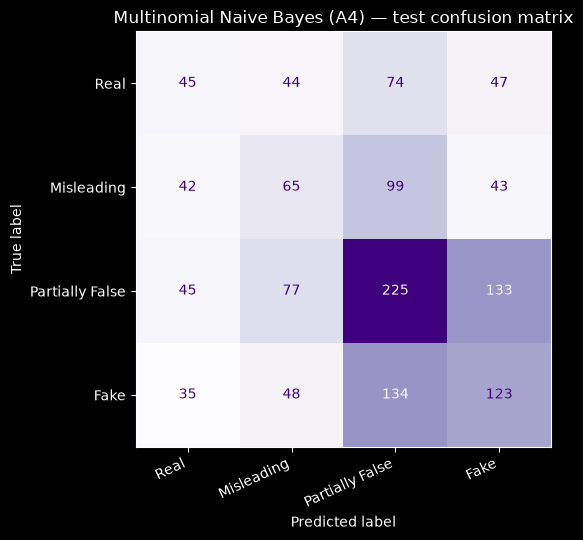

In [9]:
per_class = pd.DataFrame(test_metrics["per_class"]).T
display(per_class.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(
    np.array(test_metrics["confusion_matrix"]), display_labels=CLASS_NAMES
).plot(ax=ax, cmap="Purples", colorbar=False, values_format="d")
ax.set_title(f"{meta['display_name']} — test confusion matrix")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 9. Interpretation

Multinomial Naive Bayes applies Bayes' theorem with a strong conditional-independence assumption over terms. It is extremely fast and needs very little memory. The grid above shows that `alpha=0.1` preserves minority-class signal whereas stronger smoothing (`alpha=1.0`) pushes most predictions toward the majority class and lowers macro-F1 sharply.

## 10. Save the fitted pipeline

In [10]:
artifact_dir = PROJECT_ROOT / "models" / "notebook_artifacts"
artifact_dir.mkdir(parents=True, exist_ok=True)
artifact_path = artifact_dir / "naive_bayes.joblib"

import joblib
joblib.dump(best_pipeline, artifact_path, compress=3)
print("Saved:", artifact_path)
print("Pipeline steps:", list(best_pipeline.named_steps))

# Prove the saved artifact reproduces the same prediction after reloading.
reloaded = joblib.load(artifact_path)
sample = "The government has announced a new policy to reduce carbon emissions by 2030."
print("Reloaded prediction:", reloaded.predict([preprocess_text(sample)])[0])

Saved: /home/user/work/TruthLens-AI/models/notebook_artifacts/naive_bayes.joblib
Pipeline steps: ['features', 'classifier']
Reloaded prediction: Partially False


## 11. Conclusion

Multinomial Naive Bayes is by far the fastest model and a classic text-classification baseline. Its conditional-independence assumption is violated by real language, and a high smoothing value collapses predictions toward the majority class — visible in the validation table above.

### Limitations

* LIAR statements are short (median ≈ 99 characters) and the four classes overlap, so the task is
  genuinely hard; classical TF-IDF models typically reach the mid-to-high 30s in accuracy.
* The model learns **wording patterns**, not facts. It cannot verify a claim or detect breaking-news
  falsehoods that use ordinary vocabulary.
* Character n-grams add robustness to spelling variation but also add noise; the validation split is
  used to choose the operating configuration.

**Note on reproducibility:** every number in this notebook is computed live from the supplied CSV.
Nothing is hardcoded, and the test split is not used for tuning.